# EDA — `stackoverflow_posts.csv`

Objectif du lab : **suggérer des tags à partir du titre** d'une question Stack Overflow.
Cette EDA sert à comprendre la forme des données avant de construire les deux modèles
(un modèle classique, puis un BERT).

In [5]:
import itertools
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 1. Chargement

⚠️ Il existe un tag Stack Overflow qui s'appelle littéralement `null`. Par défaut pandas le
lit comme une valeur manquante. On compare les deux lectures.

In [6]:
raw_default = pd.read_csv("stackoverflow_posts.csv")
print("NaN dans tag_name (lecture par défaut) :", raw_default["tag_name"].isna().sum())

df = pd.read_csv("stackoverflow_posts.csv", keep_default_na=False, na_values=[])
print("NaN dans tag_name (keep_default_na=False) :", (df["tag_name"] == "").sum())
print("Lignes avec tag 'null' :", (df["tag_name"] == "null").sum())
df.shape

NaN dans tag_name (lecture par défaut) : 4
NaN dans tag_name (keep_default_na=False) : 0
Lignes avec tag 'null' : 4


(9999, 5)

In [7]:
df.head(10)

,post_id,tag_name,tag_id,tag_position,title
0,1987528,php,5,0,Is it possible to execute the procedure of a function in the scope of the caller?
1,1987531,ruby-on-rails,4984,0,ruby on rails: how to change BG color of options in select list
2,1987531,list,5608,1,ruby on rails: how to change BG color of options in select list
3,1987531,select,1151,2,ruby on rails: how to change BG color of options in select list
4,1987538,c#,9,0,How to read tags out of m4a files in .NET?
5,1987538,.net,1,1,How to read tags out of m4a files in .NET?
6,1987538,tags,115,2,How to read tags out of m4a files in .NET?
7,1987541,c#,9,0,Cannot marshal a struct that contains a union
8,1987541,c++,10,1,Cannot marshal a struct that contains a union
9,1987541,struct,1617,2,Cannot marshal a struct that contains a union


In [8]:
df.dtypes

post_id         int64
tag_name          str
tag_id          int64
tag_position    int64
title             str
dtype: object

## 2. Structure et qualité

Le fichier est au format **long** : une ligne par couple (post, tag). Le titre est répété
sur chaque ligne d'un même post.

In [9]:
checks = {
    "lignes": len(df),
    "posts distincts": df["post_id"].nunique(),
    "tags distincts": df["tag_name"].nunique(),
    "lignes dupliquées": df.duplicated().sum(),
    "couples (post, tag) dupliqués": df.duplicated(["post_id", "tag_name"]).sum(),
    "posts avec >1 titre": (df.groupby("post_id")["title"].nunique() > 1).sum(),
    "tag_name -> plusieurs tag_id": (df.groupby("tag_name")["tag_id"].nunique() > 1).sum(),
    "tag_id -> plusieurs tag_name": (df.groupby("tag_id")["tag_name"].nunique() > 1).sum(),
    "titres partagés par plusieurs posts": (df.groupby("title")["post_id"].nunique() > 1).sum(),
}
pd.Series(checks, name="valeur").to_frame()

,valeur
lignes,9999
posts distincts,4609
tags distincts,682
lignes dupliquées,0
"couples (post, tag) dupliqués",0
posts avec >1 titre,0
tag_name -> plusieurs tag_id,0
tag_id -> plusieurs tag_name,0
titres partagés par plusieurs posts,1


### `tag_position`

On s'attend à ce que chaque post ait des positions 0, 1, …, n-1. On vérifie.

In [10]:
pos = df.groupby("post_id")["tag_position"].agg(list)
contiguous = pos.apply(lambda p: sorted(p) == list(range(len(p))))
print("posts avec positions 0..n-1 contiguës :", contiguous.sum(), "/", len(pos))
print("posts sans position 0 :", (~pos.apply(lambda p: 0 in p)).sum())
df[df["post_id"].isin(pos[~contiguous].index)].head(15)

posts avec positions 0..n-1 contiguës : 4460 / 4609
posts sans position 0 : 30


,post_id,tag_name,tag_id,tag_position,title
155,1987833,wpf,378,0,How to synchronize column widths between two nested datagrids?
156,1987833,datagrid,1307,2,How to synchronize column widths between two nested datagrids?
157,1987833,binding,1137,3,How to synchronize column widths between two nested datagrids?
185,1987883,scheme,991,1,Why does this script-fu not work?
245,1987981,cordova,78331,1,PhoneGap example app does not do anything
275,1988033,android,1386,0,Use URL to show new activity?
276,1988033,android-activity,73524,2,Use URL to show new activity?
277,1988033,webview,22905,3,Use URL to show new activity?
372,1988202,java,17,1,How do I get a webpage to open up in a frame?
606,1988742,version-control,456,0,"What exactly is considered ""breaking the build?"""


## 3. Passage au format « un post = une ligne »

C'est le format dont les modèles auront besoin : un titre en entrée, une **liste de tags** en sortie
→ problème de **classification multi-label**.

In [11]:
posts = (
    df.sort_values(["post_id", "tag_position"])
      .groupby("post_id")
      .agg(title=("title", "first"), tags=("tag_name", list))
      .reset_index()
)
posts["n_tags"] = posts["tags"].str.len()
posts.head()

,post_id,title,tags,n_tags
0,1987528,Is it possible to execute the procedure of a function in the scope of the caller?,[php],1
1,1987531,ruby on rails: how to change BG color of options in select list,"[ruby-on-rails, list, select]",3
2,1987538,How to read tags out of m4a files in .NET?,"[c#, .net, tags]",3
3,1987541,Cannot marshal a struct that contains a union,"[c#, c++, struct]",3
4,1987542,libSVM automated labeller script,"[sed, awk]",2


## 4. Nombre de tags par post

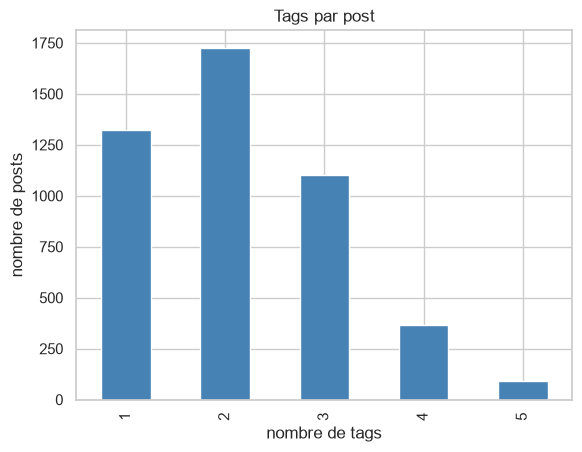

count    4609.000000
mean        2.169451
std         0.995286
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         5.000000
Name: n_tags, dtype: float64

In [12]:
ax = posts["n_tags"].value_counts().sort_index().plot.bar(color="steelblue")
ax.set(xlabel="nombre de tags", ylabel="nombre de posts", title="Tags par post")
plt.show()
posts["n_tags"].describe()

## 5. Distribution des tags

In [13]:
tag_counts = df["tag_name"].value_counts()
print("tags distincts :", len(tag_counts))
for k in [1, 2, 5, 10, 20, 50, 100]:
    print(f"tags apparaissant >= {k:>3} fois : {(tag_counts >= k).sum()}")

tags distincts : 682
tags apparaissant >=   1 fois : 682
tags apparaissant >=   2 fois : 599
tags apparaissant >=   5 fois : 392
tags apparaissant >=  10 fois : 201
tags apparaissant >=  20 fois : 86
tags apparaissant >=  50 fois : 33
tags apparaissant >= 100 fois : 18


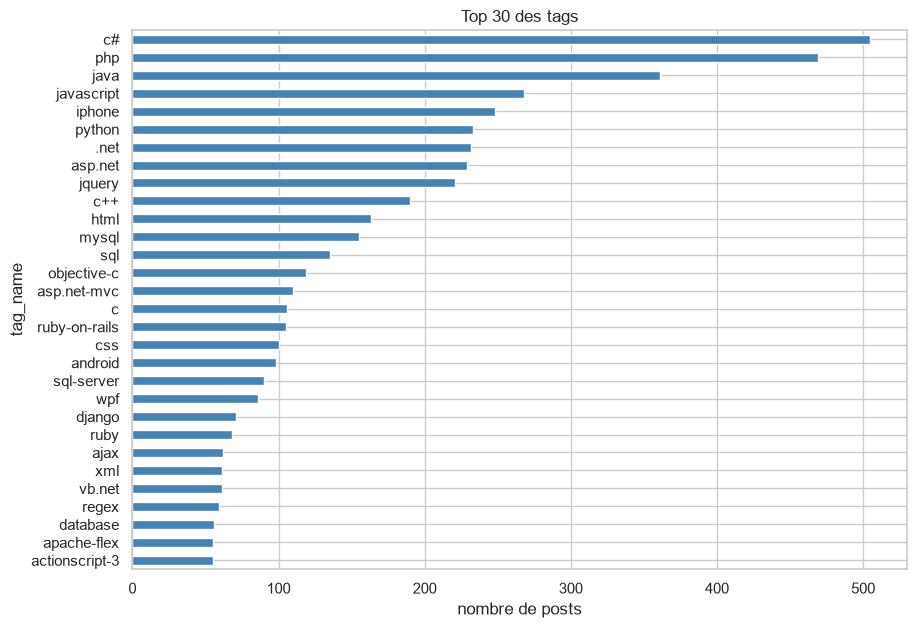

In [14]:
fig, ax = plt.subplots(figsize=(10, 7))
tag_counts.head(30).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(xlabel="nombre de posts", title="Top 30 des tags")
plt.show()

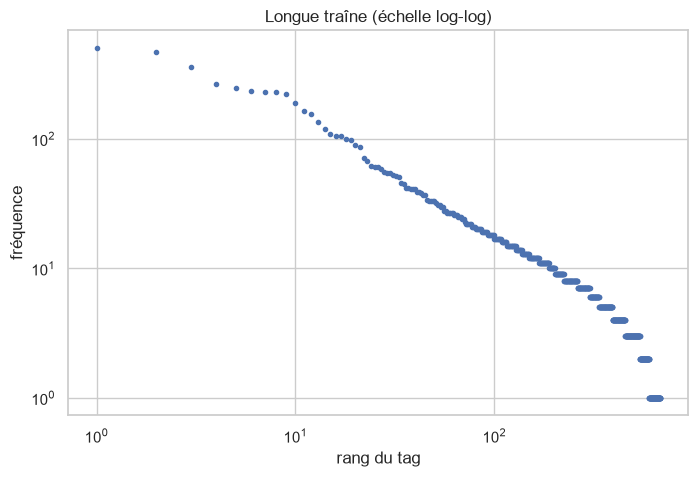

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(np.arange(1, len(tag_counts) + 1), tag_counts.values, marker=".", linestyle="none")
ax.set(xlabel="rang du tag", ylabel="fréquence", title="Longue traîne (échelle log-log)")
plt.show()

### Couverture si on ne garde que les K tags les plus fréquents

Question clé pour le choix du vocabulaire de sortie : avec K tags, quelle part des posts garde
au moins un tag, et quelle part des occurrences (post, tag) est couverte ?

In [16]:
Ks = [10, 20, 50, 100, 200, 500, len(tag_counts)]
rows = []
for k in Ks:
    keep = set(tag_counts.index[:k])
    posts_cov = posts["tags"].apply(lambda t: any(x in keep for x in t)).mean()
    occ_cov = tag_counts.iloc[:k].sum() / tag_counts.sum()
    rows.append({"K": k, "% posts avec ≥1 tag": round(100 * posts_cov, 1),
                 "% occurrences couvertes": round(100 * occ_cov, 1),
                 "fréq. min du K-ième tag": int(tag_counts.iloc[k - 1])})
coverage = pd.DataFrame(rows)
coverage

,K,% posts avec ≥1 tag,% occurrences couvertes,fréq. min du K-ième tag
0,10,56.4,29.6,190
1,20,71.0,41.4,90
2,50,83.5,55.8,33
3,100,90.4,67.2,17
4,200,95.7,80.1,10
5,500,99.4,96.8,3
6,682,100.0,100.0,1


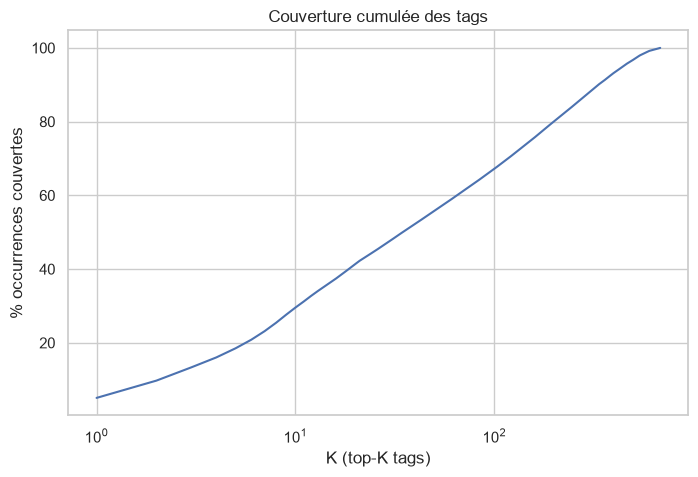

In [17]:
ks = np.arange(1, len(tag_counts) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks, tag_counts.cumsum().values / tag_counts.sum() * 100)
ax.set(xscale="log", xlabel="K (top-K tags)", ylabel="% occurrences couvertes",
       title="Couverture cumulée des tags")
plt.show()

### Tag en position 0

Le premier tag est souvent le langage / la techno principale. Si on voulait simplifier le
problème en mono-label, ce serait la cible naturelle.

In [18]:
first = df[df["tag_position"] == 0]["tag_name"].value_counts()
print("tags distincts en position 0 :", len(first))
first.head(15)

tags distincts en position 0 : 315


tag_name
c#               504
php              462
java             356
iphone           232
javascript       222
python           220
c++              184
asp.net          150
jquery           129
.net             125
sql              102
ruby-on-rails     99
html              83
c                 76
android           75
Name: count, dtype: int64

## 6. Co-occurrences entre tags fréquents

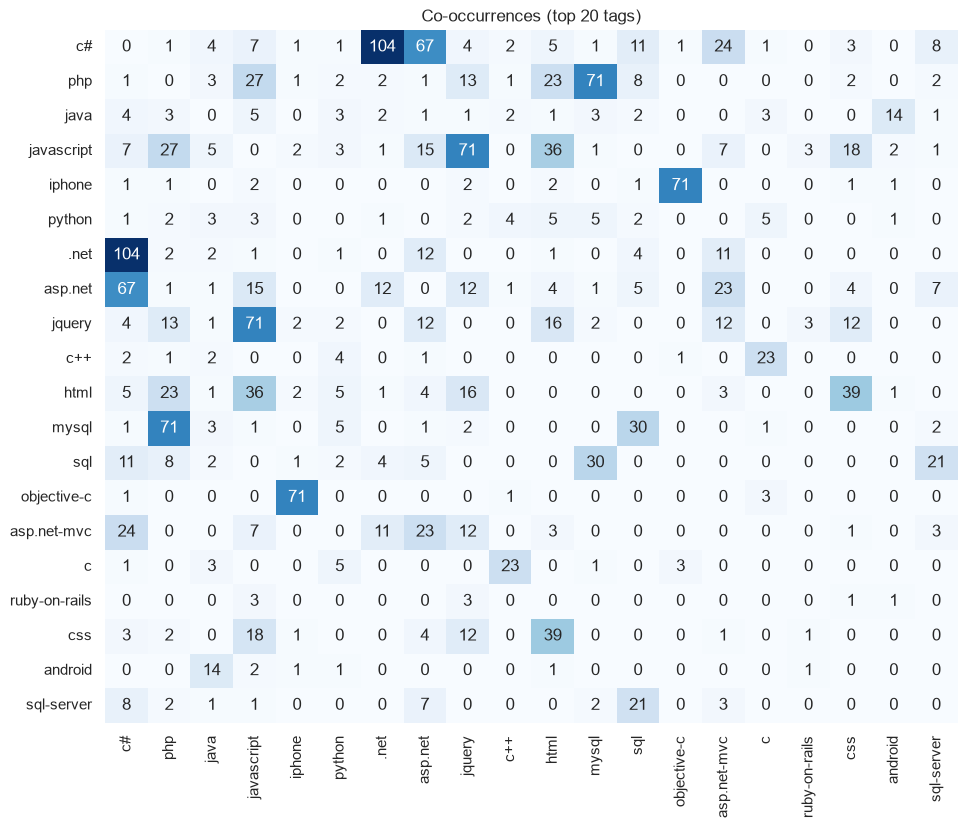

In [19]:
top = list(tag_counts.index[:20])
co = pd.DataFrame(0, index=top, columns=top)
for tags in posts["tags"]:
    t = [x for x in tags if x in top]
    for a, b in itertools.permutations(t, 2):
        co.loc[a, b] += 1

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Co-occurrences (top 20 tags)")
plt.show()

In [20]:
pairs = Counter()
for tags in posts["tags"]:
    pairs.update(itertools.combinations(sorted(set(tags)), 2))
pd.DataFrame(pairs.most_common(15), columns=["paire", "posts"])

,paire,posts
0,"(.net, c#)",104
1,"(mysql, php)",71
2,"(iphone, objective-c)",71
3,"(javascript, jquery)",71
4,"(asp.net, c#)",67
5,"(css, html)",39
6,"(html, javascript)",36
7,"(c#, wpf)",33
8,"(mysql, sql)",30
9,"(javascript, php)",27


## 7. Les titres (l'entrée des modèles)

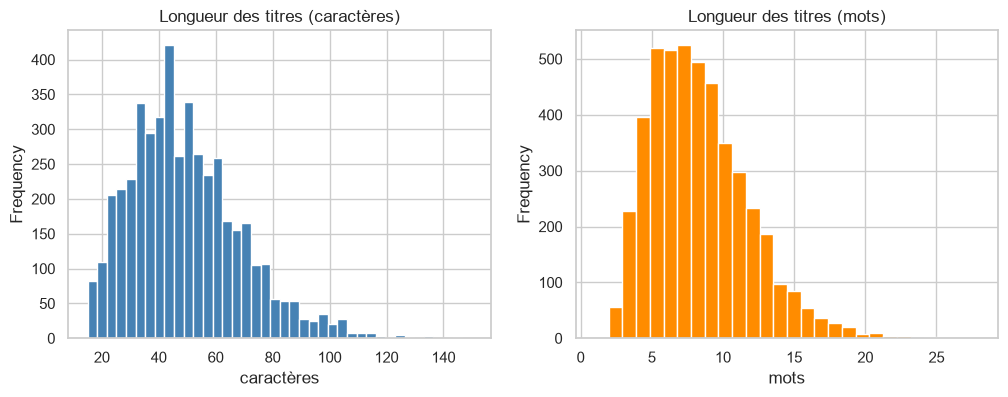

,title_chars,title_words
count,4609.000000,4609.000000
mean,49.379258,8.124973
std,19.488662,3.583818
min,15.000000,1.000000
25%,35.000000,5.000000
50%,47.000000,8.000000
75%,61.000000,10.000000
max,150.000000,28.000000


In [21]:
posts["title_chars"] = posts["title"].str.len()
posts["title_words"] = posts["title"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
posts["title_chars"].plot.hist(bins=40, ax=axes[0], color="steelblue")
axes[0].set(title="Longueur des titres (caractères)", xlabel="caractères")
posts["title_words"].plot.hist(bins=28, ax=axes[1], color="darkorange")
axes[1].set(title="Longueur des titres (mots)", xlabel="mots")
plt.show()
posts[["title_chars", "title_words"]].describe()

Les titres sont **courts** : peu de contexte par exemple. Pour BERT, une longueur max de
séquence faible (32–64 tokens) suffira.

In [22]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

tok = lambda s: re.findall(r"[a-z0-9#+.\-]+", s.lower())
words = Counter(w for t in posts["title"] for w in tok(t) if w not in ENGLISH_STOP_WORDS and len(w) > 1)
pd.DataFrame(words.most_common(30), columns=["mot", "occurrences"])

,mot,occurrences
0,using,282
1,php,215
2,file,187
3,use,158
4,java,154
5,jquery,148
6,c#,145
7,data,130
8,sql,128
9,server,124


### Le tag apparaît-il littéralement dans le titre ?

Si oui, un modèle simple (mots-clés, TF-IDF) a déjà une bonne base ; sinon, il faudra que le modèle
infère le tag à partir du contexte (ex. `UITableView` → `iphone`), là où BERT devrait apporter plus.

occurrences (post, tag) où le tag est dans le titre : 42.3%
posts avec au moins un tag dans le titre : 66.6%


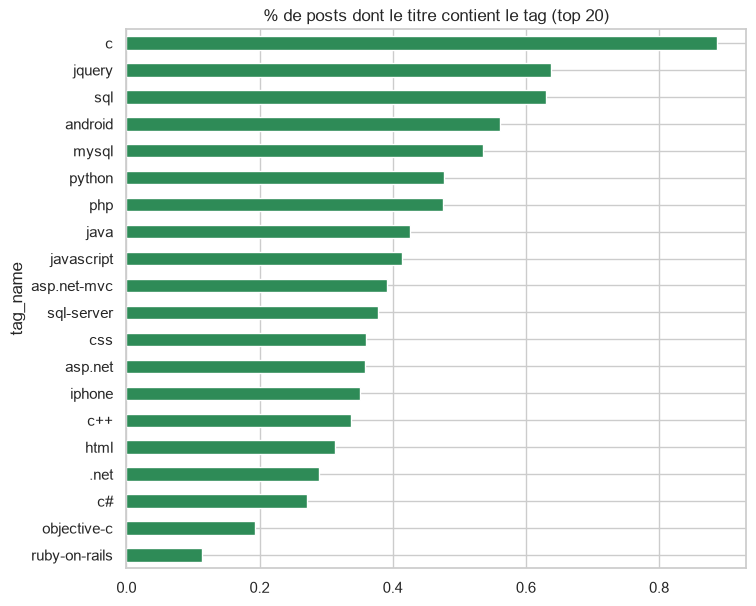

In [23]:
def tag_in_title(row):
    t = row["title"].lower()
    toks = set(tok(t))
    tag = row["tag_name"].lower()
    return tag in toks or tag.replace("-", " ") in t

df["tag_in_title"] = df.apply(tag_in_title, axis=1)
print(f"occurrences (post, tag) où le tag est dans le titre : {df['tag_in_title'].mean():.1%}")
posts_any = df.groupby("post_id")["tag_in_title"].any()
print(f"posts avec au moins un tag dans le titre : {posts_any.mean():.1%}")

(df[df["tag_name"].isin(tag_counts.index[:20])]
   .groupby("tag_name")["tag_in_title"].mean()
   .sort_values()
   .plot.barh(figsize=(8, 7), color="seagreen", title="% de posts dont le titre contient le tag (top 20)"))
plt.show()

## 8. Exemples

In [24]:
posts.sample(15, random_state=0)[['title', 'tags']]

,title,tags
3830,Jquery on curl fetched data,"[php, javascript, jquery, javascript-events, curl]"
3746,Regular HTML table border show up very strange in Firefox,"[html, firefox]"
379,Images don't show up in IE8,"[html, image, internet-explorer-8]"
3074,ORACLE 11g case insensitive by default,"[oracle, configuration, oracle11g]"
2854,How to automatically process contents of <textarea> without user pressing a button?,[ajax]
2533,Converting a web page image layout to HTML,"[html, web]"
3084,Using Python csv module on updating file,"[python, file, csv]"
2103,How do i wake a computer from being in sleep mode? in Vb 2008 expr edition,[vb.net]
1826,Cross product function in matlab,"[matlab, geometry]"
4366,ICryptoTransform.TransformFinalBlock vs ICryptoTransform.TransformBlock,[.net]


## 9. Points à retenir pour la modélisation

Les chiffres ci-dessus se lisent ainsi :

- **Problème multi-label** : environ 2 tags par post (de 1 à 5). La sortie d'un modèle est un
  ensemble de tags, pas un seul.
- **Petit dataset** : environ 4,6k posts, ce qui est peu pour des centaines de classes.
- **Longue traîne très marquée** : la plupart des tags n'apparaissent qu'une poignée de fois. Il
  faut restreindre le vocabulaire de sortie aux **top-K tags** (voir le tableau de couverture), sinon
  la plupart des classes n'ont pas assez d'exemples pour être apprises.
- **Entrées très courtes** (environ 8 mots) : TF-IDF + modèle linéaire (one-vs-rest) est une baseline
  naturelle, et pour BERT une `max_length` courte suffit.
- **Pièges de lecture** : le tag `null` (`keep_default_na=False`) et quelques posts dont les
  `tag_position` ne sont pas contiguës.
- **Split** : à faire **par `post_id`** (après regroupement), jamais par ligne, sinon un même titre se
  retrouve dans le train et le test.
- **Métriques possibles** : précision@k / rappel@k, F1 micro/macro, Hamming loss.